# Klasifikasi Keberhasilan Pemasaran Bank Menggunakan Multi-Layer Perceptron (MLP)

**Fokus eksperimen:**
1. **Feature Engineering:** menggunakan empat fitur tambahan, yaitu `pdays_contacted`, `balance_per_age`, `pdays_recency_group`, dan `campaign_intensity`, untuk membentuk informasi turunan dari fitur asli dataset.
2. **Class Weighting (Cost-Sensitive Learning):** memberikan bobot lebih besar pada kelas minoritas Yes selama proses pelatihan untuk menangani ketidakseimbangan kelas.
3. **Threshold Tuning:** menentukan ambang probabilitas optimal berdasarkan F1-score kelas `Yes` pada validation set untuk menyesuaikan keputusan klasifikasi.

1. Instalasi dan Import Library

In [2]:
!pip install ucimlrepo

In [4]:
import os
import json
import random
import platform
import warnings
import sys
import importlib.metadata
import matplotlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import sklearn
import joblib

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, roc_curve,
    precision_recall_curve
)
from sklearn.inspection import permutation_importance
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)

print("=== Versi Lingkungan & Library ===")
print(f"Python       : {sys.version.split(' ')[0]}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"Seaborn      : {sns.__version__}")
print(f"Joblib       : {joblib.__version__}")
print(f"Scikit-Learn : {sklearn.__version__}")
print(f"TensorFlow   : {tf.__version__}")
print(f"Keras        : {tf.keras.__version__}")
print(f"ucimlrepo    : {importlib.metadata.version('ucimlrepo')}")

=== Versi Lingkungan & Library ===
Python       : 3.13.18
NumPy        : 2.4.6
Pandas       : 2.2.3
Matplotlib   : 3.10.0
Seaborn      : 0.13.2
Joblib       : 1.6.0
Scikit-Learn : 1.6.1
TensorFlow   : 2.21.0
Keras        : 3.13.2
ucimlrepo    : 0.0.7


2. Load Dataset UCI Bank Marketing

In [5]:
bank = fetch_ucirepo(id=222)
X_raw = bank.data.features.copy()
target_raw = bank.data.targets.iloc[:, 0].copy()

y = (
    target_raw.astype(str)
    .str.strip()
    .str.lower()
    .map({"no": 0, "yes": 1})
)

if y.isna().any():
    raise ValueError("Target mengandung label selain 'yes'/'no'.")

y = y.astype("int32")
df_raw = X_raw.copy()
df_raw["target"] = y

print("Ukuran dataset:", df_raw.shape)
print("Jumlah fitur asli:", X_raw.shape[1])
print("Jumlah duplikat:", df_raw.duplicated().sum())
display(df_raw.head())
display(df_raw.dtypes.rename("dtype").to_frame())
display(df_raw.isna().sum().rename("missing").to_frame())
display(df_raw["target"].value_counts().rename(index={0: "No", 1: "Yes"}).to_frame("jumlah"))

Ukuran dataset: (45211, 17)
Jumlah fitur asli: 16
Jumlah duplikat: 0


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,target
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,0
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,0
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,0
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,0


,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day_of_week,int64


,missing
age,0
job,288
marital,0
education,1857
default,0
balance,0
housing,0
loan,0
contact,13020
day_of_week,0


,jumlah
target,
No,39922
Yes,5289


3. Exploratory Data Analysis (EDA)

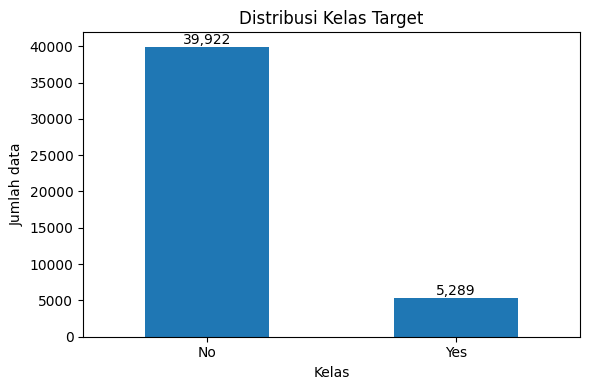

Persentase kelas (%):


,persentase
target,
No,88.3
Yes,11.7


In [6]:
class_counts = df_raw["target"].value_counts().sort_index()
class_percent = (class_counts / len(df_raw) * 100).round(2)

ax = class_counts.rename(index={0: "No", 1: "Yes"}).plot(
    kind="bar", figsize=(6, 4), rot=0
)
ax.set_title("Distribusi Kelas Target")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah data")
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom"
    )
plt.tight_layout()
plt.show()

print("Persentase kelas (%):")
display(class_percent.rename(index={0: "No", 1: "Yes"}).to_frame("persentase"))

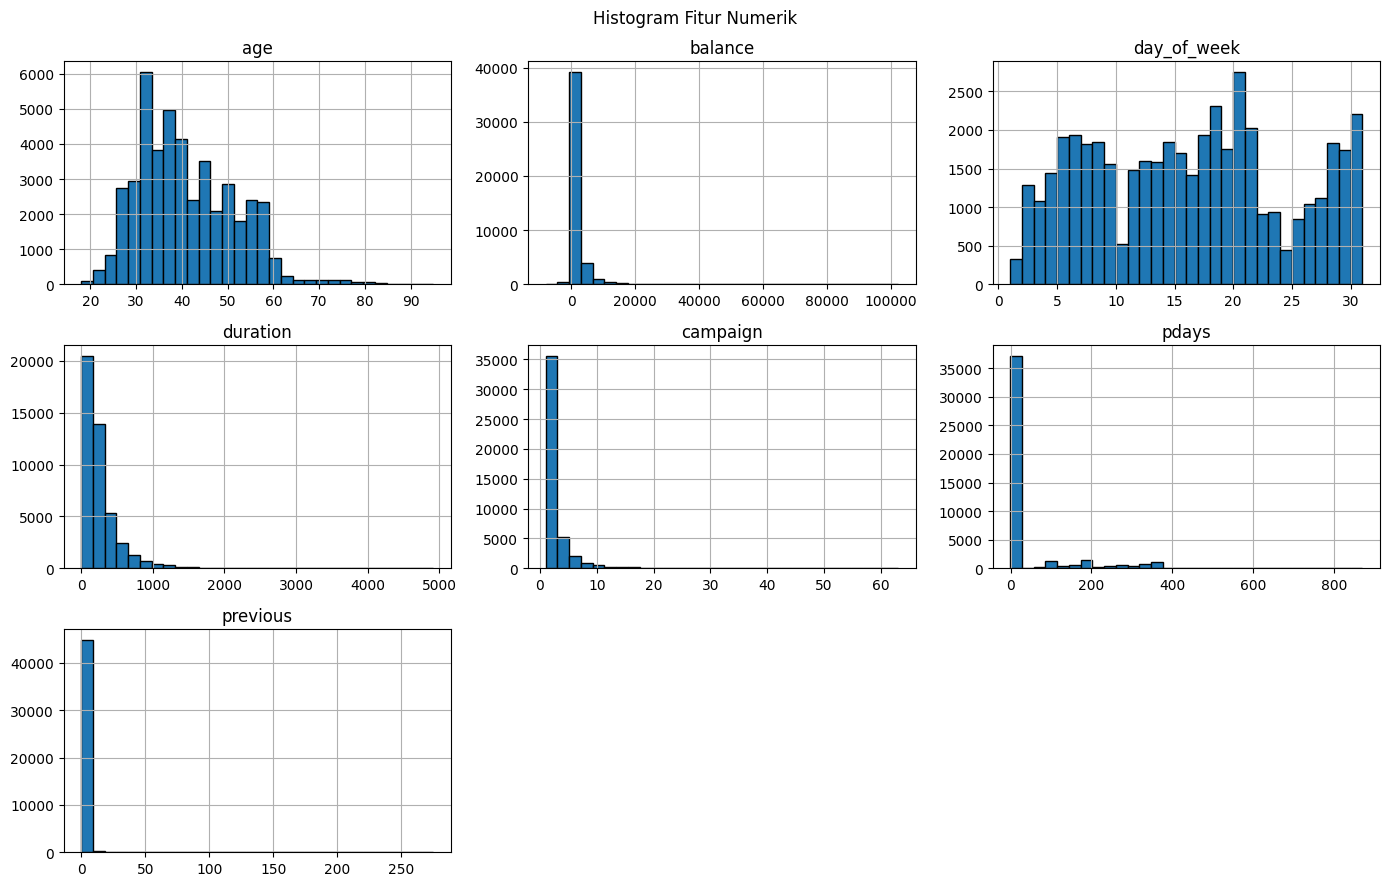

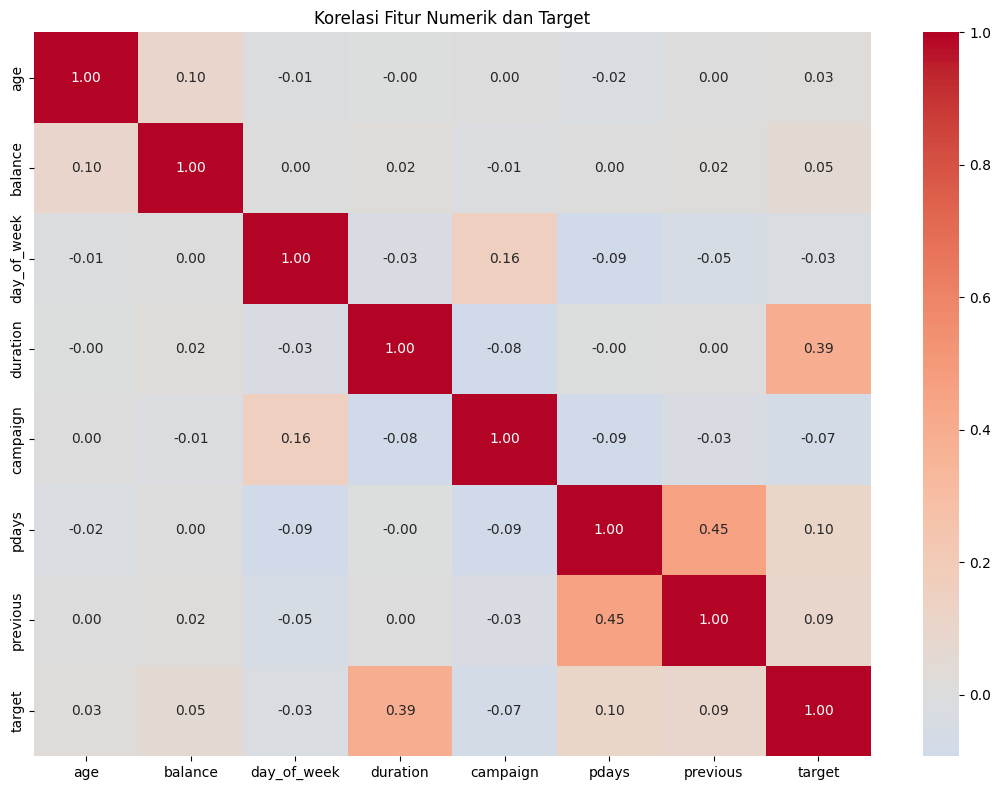

In [7]:
numeric_eda = df_raw.select_dtypes(include=np.number).columns.drop("target", errors="ignore")
df_raw[numeric_eda].hist(figsize=(14, 9), bins=30, edgecolor="black")
plt.suptitle("Histogram Fitur Numerik")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 8))
sns.heatmap(
    df_raw[list(numeric_eda) + ["target"]].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0
)
plt.title("Korelasi Fitur Numerik dan Target")
plt.tight_layout()
plt.show()

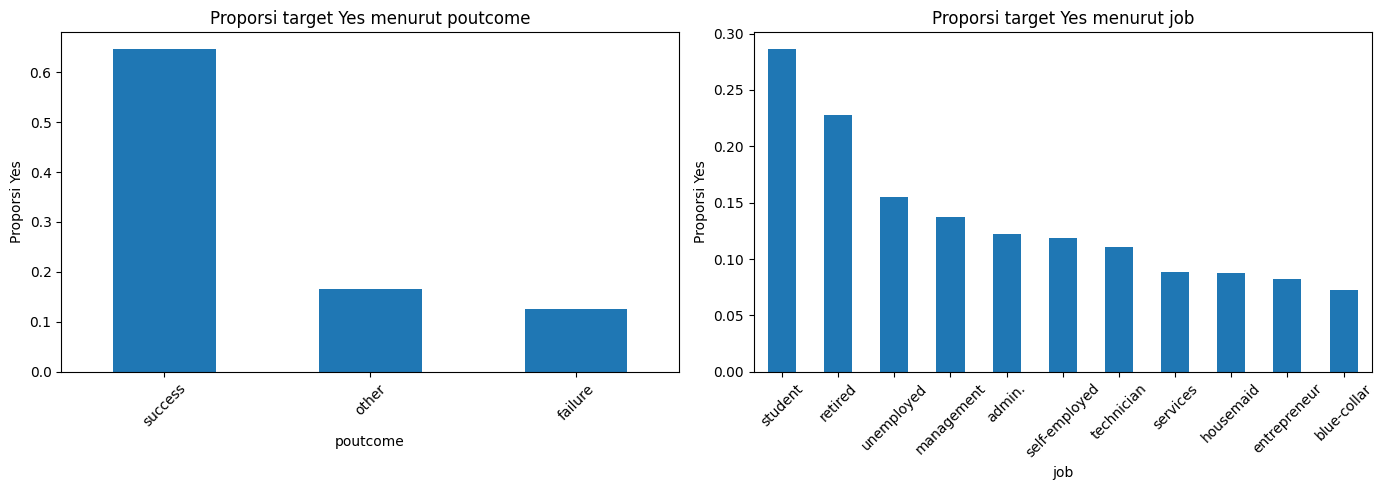

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for col, ax in zip(["poutcome", "job"], axes):
    (df_raw.groupby(col, observed=False)["target"].mean()
     .sort_values(ascending=False)
     .plot(kind="bar", ax=ax))
    ax.set_title(f"Proporsi target Yes menurut {col}")
    ax.set_ylabel("Proporsi Yes")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Ringkasan temuan EDA
- Dataset berisi 45.211 observasi dan 16 fitur asli.
- Target terdiri dari kelas `No` sebanyak 39.922 (sekitar 88,3%) dan kelas `Yes` sebanyak 5.289 (sekitar 11,7%).
- Distribusi target tidak seimbang. Karena itu, accuracy saja tidak cukup untuk menilai model; precision, recall, F1 kelas `Yes`, ROC-AUC, dan PR-AUC juga digunakan.
- Beberapa fitur kategorikal memiliki nilai kosong. Imputasi akan dipelajari dari training set untuk mencegah data leakage.

4. Pembersihan data, feature engineering, dan pembagian data

In [9]:
X = X_raw.copy()
if "duration" in X.columns:
    X = X.drop(columns=["duration"])

# Fitur tambahan 1: indikator apakah nasabah pernah dihubungi sebelumnya.
pdays_num = pd.to_numeric(X["pdays"], errors="coerce")
X["pdays_contacted"] = (pdays_num != -1).astype("int8")

# Fitur tambahan 2: rasio saldo terhadap usia.
X["balance_per_age"] = (
    pd.to_numeric(X["balance"], errors="coerce") /
    pd.to_numeric(X["age"], errors="coerce").replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan)

# Fitur tambahan 3: kelompok jarak hari sejak kontak kampanye sebelumnya.
X["pdays_recency_group"] = np.select(
    [
        pdays_num.eq(-1),
        pdays_num.ge(0) & pdays_num.le(30),
        pdays_num.ge(31) & pdays_num.le(90),
        pdays_num.gt(90)
    ],
    ["Never_contacted", "Recent_0_30_days", "Medium_31_90_days", "Long_over_90_days"],
    default="Unknown"
)

# Fitur tambahan 4: kelompok intensitas kontak pada kampanye saat ini.
campaign_num = pd.to_numeric(X["campaign"], errors="coerce")
X["campaign_intensity"] = np.select(
    [
        campaign_num.eq(1),
        campaign_num.ge(2) & campaign_num.le(3),
        campaign_num.ge(4)
    ],
    ["Low_1_contact", "Medium_2_3_contacts", "High_4plus_contacts"],
    default="Unknown"
)

added_features = [
    "pdays_contacted", "balance_per_age",
    "pdays_recency_group", "campaign_intensity"
]
print("Kolom duration dihapus:", "duration" not in X.columns)
print("Fitur tambahan:", added_features)
print("Jumlah fitur sebelum encoding:", X.shape[1])
print("\nDistribusi pdays_recency_group:")
display(X["pdays_recency_group"].value_counts(dropna=False).to_frame("jumlah"))
print("\nDistribusi campaign_intensity:")
display(X["campaign_intensity"].value_counts(dropna=False).to_frame("jumlah"))


Kolom duration dihapus: True
Fitur tambahan: ['pdays_contacted', 'balance_per_age', 'pdays_recency_group', 'campaign_intensity']
Jumlah fitur sebelum encoding: 19

Distribusi pdays_recency_group:


,jumlah
pdays_recency_group,
Never_contacted,36954
Long_over_90_days,7539
Medium_31_90_days,530
Recent_0_30_days,188



Distribusi campaign_intensity:


,jumlah
campaign_intensity,
Medium_2_3_contacts,18026
Low_1_contact,17544
High_4plus_contacts,9641


### Empat Fitur Unik Hasil Feature Engineering

Dalam penelitian ini, digunakan empat fitur tambahan (*engineered features*) yang dibentuk dari kolom asli dataset Bank Marketing. Fitur-fitur tersebut dirancang untuk merepresentasikan informasi turunan yang mungkin membantu model MLP mengenali pola keberhasilan pemasaran. Pengaruhnya tetap perlu dibuktikan melalui evaluasi model.

**1. `pdays_contacted` (Indikator Riwayat Kontak)**

Fitur ini merupakan variabel biner yang menunjukkan apakah nasabah pernah dihubungi dalam kampanye sebelumnya. Fitur dibentuk berdasarkan kolom `pdays`, dengan nilai 1 jika `pdays` tidak sama dengan -1 dan nilai 0 jika `pdays` sama dengan -1.

Penambahan fitur ini bertujuan memisahkan informasi status riwayat kontak nasabah dari informasi jarak hari sejak kontak sebelumnya.

**2. `balance_per_age` (Rasio Saldo terhadap Usia)**

Fitur ini merupakan variabel numerik yang dibentuk dengan membagi saldo rekening nasabah (`balance`) dengan usia nasabah (`age`).

Rumus:

`balance_per_age = balance / age`

Fitur ini bertujuan memberikan informasi tambahan mengenai perbandingan saldo rekening terhadap usia nasabah. Nilai usia 0 dan hasil perhitungan yang tidak valid ditangani sebagai missing value (`NaN`).

**3. `pdays_recency_group` (Kelompok Jarak Kontak Sebelumnya)**

Mengelompokkan nilai `pdays` berdasarkan jarak hari sejak nasabah terakhir kali dihubungi:
- `Never_contacted`: `pdays = -1` (belum pernah dihubungi sebelumnya).
- `Recent_0_30_days`: 0–30 hari.
- `Medium_31_90_days`: 31–90 hari.
- `Long_over_90_days`: lebih dari 90 hari.
- `Unknown`: nilai yang tidak termasuk kondisi di atas atau tidak valid.

Fitur ini memberikan kategori rentang waktu, sedangkan `pdays_contacted` hanya menyatakan pernah/tidaknya kontak sebelumnya.

**4. `campaign_intensity` (Kelompok Intensitas Kontak Kampanye Saat Ini)**

Mengelompokkan jumlah kontak pada kampanye saat ini (campaign) menjadi:
- `Low_1_contact`: 1 kontak.
- `Medium_2_3_contacts`: 2–3 kontak.
- `High_4plus_contacts`: 4 kontak atau lebih.
- `Unknown`: nilai yang tidak valid atau tidak termasuk kondisi di atas.

Keempat fitur tersebut ditambahkan ke input model. Pengaruh fitur akan dievaluasi melalui Permutation Importance dan Ablation Study. Batas kategori merupakan aturan rekayasa fitur yang ditetapkan dalam eksperimen, bukan batas klinis atau ketentuan baku dari dataset.

In [10]:
# Split stratified 70:15:15
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.1764705882, random_state=SEED,
    stratify=y_train_full
)

split_summary = pd.DataFrame({
    "Subset": ["Train", "Validation", "Test"],
    "Jumlah": [len(y_train), len(y_val), len(y_test)],
    "Persentase": [len(y_train) / len(y), len(y_val) / len(y), len(y_test) / len(y)],
    "Proporsi Yes": [y_train.mean(), y_val.mean(), y_test.mean()]
})
display(split_summary.round(4))

,Subset,Jumlah,Persentase,Proporsi Yes
0,Train,31647,0.70,0.1170
1,Validation,6782,0.15,0.1169
2,Test,6782,0.15,0.1169


5. Preprocessing tanpa data leakage

In [11]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

medians = X_train[numeric_features].median()
modes = {}
for col in categorical_features:
    mode_values = X_train[col].mode(dropna=True)
    modes[col] = mode_values.iloc[0] if len(mode_values) else "unknown"

def preprocess_features(frame):
    """Imputasi dan one-hot encoding dengan parameter dari training set."""
    data = frame.copy()
    for col in numeric_features:
        data[col] = pd.to_numeric(data[col], errors="coerce").fillna(medians[col])
    for col in categorical_features:
        data[col] = data[col].fillna(modes[col]).astype(str)
    return pd.get_dummies(data, drop_first=True, dtype=float)

X_train_encoded = preprocess_features(X_train)
feature_columns = X_train_encoded.columns.tolist()
X_val_encoded = preprocess_features(X_val).reindex(columns=feature_columns, fill_value=0)
X_test_encoded = preprocess_features(X_test).reindex(columns=feature_columns, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded).astype("float32")
X_val_scaled = scaler.transform(X_val_encoded).astype("float32")
X_test_scaled = scaler.transform(X_test_encoded).astype("float32")

print("Jumlah fitur setelah encoding:", len(feature_columns))
print("Shape train:", X_train_scaled.shape)
print("Shape validation:", X_val_scaled.shape)
print("Shape test:", X_test_scaled.shape)
assert X_train_scaled.shape[1] == X_val_scaled.shape[1] == X_test_scaled.shape[1]

print("Missing value setelah preprocessing:")
print(X_train_encoded.isna().sum().sum())
print(X_val_encoded.isna().sum().sum())
print(X_test_encoded.isna().sum().sum())

Jumlah fitur setelah encoding: 44
Shape train: (31647, 44)
Shape validation: (6782, 44)
Shape test: (6782, 44)
Missing value setelah preprocessing:
0
0
0


6. TensorFlow input pipeline menggunakan tf.data

In [ ]:
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

y_train_np = y_train.to_numpy(dtype="int32")
y_val_np = y_val.to_numpy(dtype="int32")
y_test_np = y_test.to_numpy(dtype="int32")

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train_scaled, y_train_np))
    .shuffle(len(X_train_scaled), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_dataset = (
    tf.data.Dataset.from_tensor_slices((X_val_scaled, y_val_np))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test_scaled, y_test_np))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Train batches:", len(train_dataset))
print("Validation batches:", len(val_dataset))
print("Test batches:", len(test_dataset))

Train batches: 495
Validation batches: 106
Test batches: 106


7. Fungsi Evaluasi dan Metrik

In [ ]:
def get_prob(model, X_array):
    return model.predict(X_array, verbose=0).ravel()

def metric_row(y_true, probabilities, threshold=0.5, name="Model"):
    y_pred = (np.asarray(probabilities) >= threshold).astype(int)
    return {
        "Skenario": name,
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_yes": precision_score(y_true, y_pred, zero_division=0),
        "Recall_yes": recall_score(y_true, y_pred, zero_division=0),
        "F1_yes": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities)
    }

THRESHOLD_GRID = np.round(np.arange(0.10, 0.91, 0.01), 2)

def find_best_threshold(y_true, probabilities, model_name):
    rows = [
        metric_row(y_true, probabilities, threshold, model_name)
        for threshold in THRESHOLD_GRID
    ]
    table = pd.DataFrame(rows)
    best = table.sort_values(
        ["F1_yes", "Precision_yes"], ascending=False
    ).iloc[0]
    return float(best["Threshold"]), table, best

8. Eksperimen Penanganan Ketidakseimbangan Kelas – Class Weighting

In [ ]:
classes = np.array([0, 1])
class_weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train
)
class_weight_dict = {
    int(label): float(weight)
    for label, weight in zip(classes, class_weights)
}
print("Class weight:", class_weight_dict)

sample_weights = np.array(
    [class_weight_dict[int(label)] for label in y_train_np],
    dtype="float32"
)
train_dataset_weighted = (
    tf.data.Dataset.from_tensor_slices(
        (X_train_scaled, y_train_np, sample_weights)
    )
    .shuffle(len(X_train_scaled), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
print("Weighted dataset batches:", len(train_dataset_weighted))

Class weight: {0: 0.5662575150300602, 1: 4.273156899810964}
Weighted dataset batches: 495


9. Arsitektur MLP dengan Callback

In [ ]:
def build_mlp(input_dim, tuned=False):
    if not tuned:
        model = keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation="relu"),
            layers.BatchNormalization(),
            layers.Dropout(0.30),
            layers.Dense(32, activation="relu"),
            layers.BatchNormalization(),
            layers.Dropout(0.20),
            layers.Dense(16, activation="relu"),
            layers.Dense(1, activation="sigmoid")
        ], name="MLP_Baseline")
        learning_rate = 1e-3
    else:
        model = keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
            layers.BatchNormalization(),
            layers.Dropout(0.30),
            layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
            layers.BatchNormalization(),
            layers.Dropout(0.25),
            layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
            layers.Dense(1, activation="sigmoid")
        ], name="MLP_Tuned")
        learning_rate = 3e-4

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="roc_auc"),
            keras.metrics.AUC(name="pr_auc", curve="PR")
        ]
    )
    return model

def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_pr_auc", mode="max", patience=8,
            restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", mode="min", factor=0.5,
            patience=4, min_lr=1e-6, verbose=1
        )
    ]

10. Eksperimen dampak Class Weighting

In [ ]:
def train_weighting_experiment(use_class_weight):
    tf.keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_mlp(X_train_scaled.shape[1], tuned=True)
    dataset = train_dataset_weighted if use_class_weight else train_dataset
    history = model.fit(
        dataset,
        validation_data=val_dataset,
        epochs=100,
        callbacks=make_callbacks(),
        verbose=1
    )
    return model, history

model_no_weight, history_no_weight = train_weighting_experiment(False)
model_with_weight, history_with_weight = train_weighting_experiment(True)

prob_no_weight = get_prob(model_no_weight, X_val_scaled)
prob_with_weight = get_prob(model_with_weight, X_val_scaled)

threshold_no_weight, threshold_table_no_weight, best_no_weight = find_best_threshold(
    y_val, prob_no_weight, "Tuned tanpa Class Weight"
)
threshold_with_weight, threshold_table_with_weight, best_with_weight = find_best_threshold(
    y_val, prob_with_weight, "Tuned dengan Class Weight"
)

class_weight_comparison = pd.DataFrame([
    metric_row(y_val, prob_no_weight, 0.50, "Tanpa Class Weight @ 0.50"),
    metric_row(y_val, prob_with_weight, 0.50, "Dengan Class Weight @ 0.50"),
    metric_row(y_val, prob_no_weight, threshold_no_weight,
               f"Tanpa Class Weight @ {threshold_no_weight:.2f}"),
    metric_row(y_val, prob_with_weight, threshold_with_weight,
               f"Dengan Class Weight @ {threshold_with_weight:.2f}")
])
display(class_weight_comparison.round(4))

print("Threshold terbaik tanpa class weight:", threshold_no_weight)
print("Threshold terbaik dengan class weight:", threshold_with_weight)

Epoch 1/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.7585 - loss: 0.5496 - pr_auc: 0.1956 - roc_auc: 0.6159 - val_accuracy: 0.8876 - val_loss: 0.3454 - val_pr_auc: 0.3283 - val_roc_auc: 0.7003 - learning_rate: 3.0000e-04
Epoch 2/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8867 - loss: 0.3555 - pr_auc: 0.3070 - roc_auc: 0.6922 - val_accuracy: 0.8907 - val_loss: 0.3372 - val_pr_auc: 0.3667 - val_roc_auc: 0.7308 - learning_rate: 3.0000e-04
Epoch 3/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.8885 - loss: 0.3426 - pr_auc: 0.3380 - roc_auc: 0.7145 - val_accuracy: 0.8916 - val_loss: 0.3317 - val_pr_auc: 0.3809 - val_roc_auc: 0.7433 - learning_rate: 3.0000e-04
Epoch 4/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8909 - loss: 0.3359 - pr_auc: 0.3607 - roc_auc: 0.7263 - val_accuracy: 0.8912 - val_loss: 0.3273 - val_pr_auc: 0.3888 - val_roc_auc: 0.7524 - learning_rate: 3.0000e-04
Epoch 5/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - ac

,Skenario,Threshold,Accuracy,Precision_yes,Recall_yes,F1_yes,ROC_AUC,PR_AUC
0,Tanpa Class Weight @ 0.50,0.50,0.8937,0.6241,0.2282,0.3343,0.7729,0.4391
1,Dengan Class Weight @ 0.50,0.50,0.8154,0.3314,0.5687,0.4188,0.7729,0.4127
2,Tanpa Class Weight @ 0.20,0.20,0.8704,0.4496,0.4842,0.4663,0.7729,0.4391
3,Dengan Class Weight @ 0.58,0.58,0.8531,0.3982,0.5006,0.4436,0.7729,0.4127


Threshold terbaik tanpa class weight: 0.2
Threshold terbaik dengan class weight: 0.58


11. Training Model Baseline dan Tuned

In [ ]:
# Baseline
tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model_baseline = build_mlp(X_train_scaled.shape[1], tuned=False)
history_baseline = model_baseline.fit(
    train_dataset_weighted,
    validation_data=val_dataset,
    epochs=80,
    callbacks=make_callbacks(),
    verbose=1
)

# Tuned
tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model_tuned = build_mlp(X_train_scaled.shape[1], tuned=True)
history_tuned = model_tuned.fit(
    train_dataset_weighted,
    validation_data=val_dataset,
    epochs=100,
    callbacks=make_callbacks(),
    verbose=1
)

print("Arsitektur Baseline:")
model_baseline.summary()
print("Arsitektur Tuned:")
model_tuned.summary()

Epoch 1/80
495/495 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6526 - loss: 0.6494 - pr_auc: 0.2789 - roc_auc: 0.6695 - val_accuracy: 0.7903 - val_loss: 0.5553 - val_pr_auc: 0.3844 - val_roc_auc: 0.7433 - learning_rate: 0.0010
Epoch 2/80
495/495 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7328 - loss: 0.6000 - pr_auc: 0.3575 - roc_auc: 0.7281 - val_accuracy: 0.8250 - val_loss: 0.5048 - val_pr_auc: 0.3976 - val_roc_auc: 0.7553 - learning_rate: 0.0010
Epoch 3/80
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7571 - loss: 0.5921 - pr_auc: 0.3590 - roc_auc: 0.7419 - val_accuracy: 0.8001 - val_loss: 0.5294 - val_pr_auc: 0.4064 - val_roc_auc: 0.7633 - learning_rate: 0.0010
Epoch 4/80
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7563 - loss: 0.5848 - pr_auc: 0.3757 - roc_auc: 0.7485 - val_accuracy: 0.8099 - val_loss: 0.5277 - val_pr_auc: 0.4099 - val_roc_auc: 0.7634 - learning_rate: 0.0010
Epoch 5/80
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7605 - loss: 0

Model: "MLP_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,285 (67.52 KB)

 Trainable params: 5,697 (22.25 KB)

 Non-trainable params: 192 (768.00 B)

... (4 outputs left out)

 Total params: 49,925 (195.02 KB)

 Trainable params: 16,513 (64.50 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 33,028 (129.02 KB)

12. Perbandingan Kandidat Model pada Validation Set dan Pemilihan Model Final

In [ ]:
val_base_probs = get_prob(model_baseline, X_val_scaled)
val_tuned_probs = get_prob(model_tuned, X_val_scaled)
val_no_weight_probs = get_prob(model_no_weight, X_val_scaled)

validation_comparison = pd.DataFrame([
    metric_row(y_val, val_base_probs, 0.50, "Baseline dengan Class Weight @ 0.50"),
    metric_row(y_val, val_tuned_probs, 0.50, "Tuned dengan Class Weight @ 0.50"),
    metric_row(y_val, val_no_weight_probs, 0.50, "Tuned tanpa Class Weight @ 0.50")
])
display(validation_comparison.round(4))

baseline_threshold, baseline_threshold_df, baseline_best = find_best_threshold(
    y_val, val_base_probs, "Baseline dengan Class Weight"
)
tuned_threshold, tuned_threshold_df, tuned_best = find_best_threshold(
    y_val, val_tuned_probs, "Tuned dengan Class Weight"
)
no_weight_threshold, no_weight_threshold_df, no_weight_best = find_best_threshold(
    y_val, val_no_weight_probs, "Tuned tanpa Class Weight"
)

threshold_comparison = pd.DataFrame([
    baseline_best,
    tuned_best,
    no_weight_best
])
display(threshold_comparison.round(4))

selected_row = threshold_comparison.sort_values(
    ["F1_yes", "Precision_yes", "PR_AUC", "ROC_AUC"],
    ascending=False
).iloc[0]

selected_name = str(selected_row["Skenario"])

model_candidates = {
    "Baseline dengan Class Weight": model_baseline,
    "Tuned dengan Class Weight": model_tuned,
    "Tuned tanpa Class Weight": model_no_weight
}
threshold_candidates = {
    "Baseline dengan Class Weight": baseline_threshold,
    "Tuned dengan Class Weight": tuned_threshold,
    "Tuned tanpa Class Weight": no_weight_threshold
}
probability_candidates = {
    "Baseline dengan Class Weight": val_base_probs,
    "Tuned dengan Class Weight": val_tuned_probs,
    "Tuned tanpa Class Weight": val_no_weight_probs
}

selected_model = model_candidates[selected_name]
best_threshold = float(threshold_candidates[selected_name])
selected_val_probs = probability_candidates[selected_name]

selected_architecture = (
    "Baseline" if selected_name.startswith("Baseline") else "Tuned"
)
selected_uses_class_weight = selected_name != "Tuned tanpa Class Weight"

print("Model terpilih:", selected_name)
print("Arsitektur:", selected_architecture)
print("Menggunakan class weighting:", selected_uses_class_weight)
print("Threshold final dari validation:", best_threshold)

,Skenario,Threshold,Accuracy,Precision_yes,Recall_yes,F1_yes,ROC_AUC,PR_AUC
0,Baseline dengan Class Weight @ 0.50,0.5,0.8076,0.3230,0.5889,0.4172,0.7724,0.4162
1,Tuned dengan Class Weight @ 0.50,0.5,0.8130,0.3295,0.5788,0.4199,0.7729,0.4266
2,Tuned tanpa Class Weight @ 0.50,0.5,0.8937,0.6241,0.2282,0.3343,0.7729,0.4391


,Skenario,Threshold,Accuracy,Precision_yes,Recall_yes,F1_yes,ROC_AUC,PR_AUC
57,Baseline dengan Class Weight,0.67,0.8704,0.4470,0.4578,0.4523,0.7724,0.4162
55,Tuned dengan Class Weight,0.65,0.8677,0.4385,0.4678,0.4527,0.7729,0.4266
10,Tuned tanpa Class Weight,0.20,0.8704,0.4496,0.4842,0.4663,0.7729,0.4391


Model terpilih: Tuned tanpa Class Weight
Arsitektur: Tuned
Menggunakan class weighting: False
Threshold final dari validation: 0.2


13. Eksperimen Optimasi Threshold – Threshold Tuning

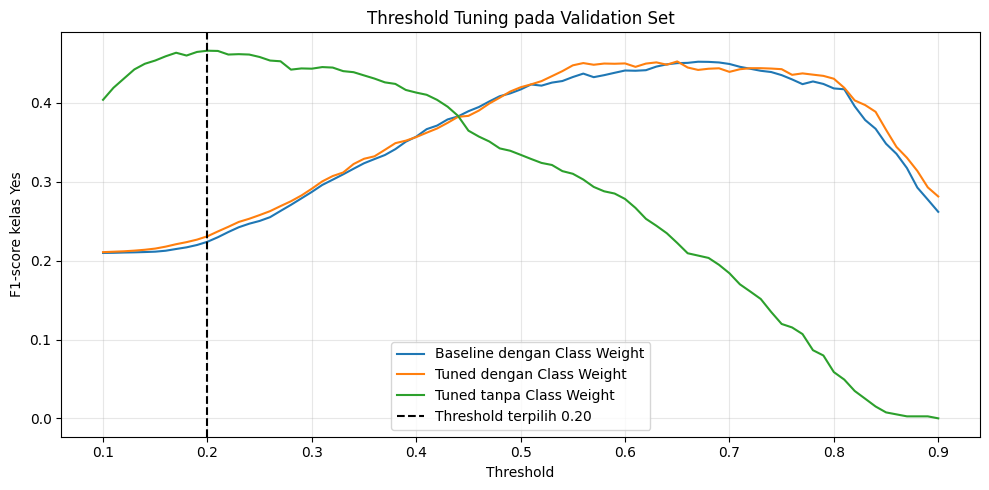

,Skenario,Threshold,Accuracy,Precision_yes,Recall_yes,F1_yes,ROC_AUC,PR_AUC
0,Tuned tanpa Class Weight @ 0.50,0.5,0.8937,0.6241,0.2282,0.3343,0.7729,0.4391
1,Tuned tanpa Class Weight @ 0.20,0.2,0.8704,0.4496,0.4842,0.4663,0.7729,0.4391


In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(
    baseline_threshold_df["Threshold"],
    baseline_threshold_df["F1_yes"],
    label="Baseline dengan Class Weight"
)
plt.plot(
    tuned_threshold_df["Threshold"],
    tuned_threshold_df["F1_yes"],
    label="Tuned dengan Class Weight"
)
plt.plot(
    no_weight_threshold_df["Threshold"],
    no_weight_threshold_df["F1_yes"],
    label="Tuned tanpa Class Weight"
)
plt.axvline(
    best_threshold,
    linestyle="--",
    color="black",
    label=f"Threshold terpilih {best_threshold:.2f}"
)
plt.xlabel("Threshold")
plt.ylabel("F1-score kelas Yes")
plt.title("Threshold Tuning pada Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

threshold_impact = pd.DataFrame([
    metric_row(y_val, selected_val_probs, 0.50, f"{selected_name} @ 0.50"),
    metric_row(
        y_val, selected_val_probs, best_threshold,
        f"{selected_name} @ {best_threshold:.2f}"
    )
])
display(threshold_impact.round(4))

14. Evaluasi Final pada test set

,Skenario,Threshold,Accuracy,Precision_yes,Recall_yes,F1_yes,ROC_AUC,PR_AUC
0,Final Tuned tanpa Class Weight @ 0.20,0.2,0.8657,0.4312,0.4666,0.4482,0.7713,0.3959


Classification report – model final:
              precision    recall  f1-score   support

          No       0.93      0.92      0.92      5989
         Yes       0.43      0.47      0.45       793

    accuracy                           0.87      6782
   macro avg       0.68      0.69      0.69      6782
weighted avg       0.87      0.87      0.87      6782



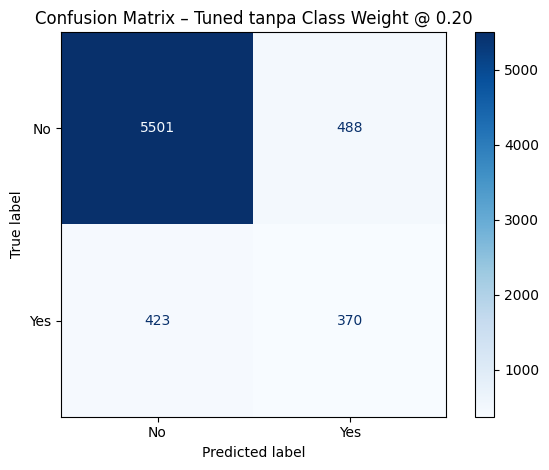

Confusion matrix [[TN, FP], [FN, TP]]:
[[5501  488]
 [ 423  370]]


In [ ]:
test_selected_probs = selected_model.predict(test_dataset, verbose=0).ravel()
final_pred = (test_selected_probs >= best_threshold).astype(int)

test_results = pd.DataFrame([
    metric_row(y_test, test_selected_probs, best_threshold,
               f"Final {selected_name} @ {best_threshold:.2f}")
])
display(test_results.round(4))

print("Classification report – model final:")
print(classification_report(
    y_test, final_pred, target_names=["No", "Yes"], zero_division=0
))

cm = confusion_matrix(y_test, final_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["No", "Yes"]
).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix – {selected_name} @ {best_threshold:.2f}")
plt.tight_layout()
plt.show()
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)

15. Grafik training dan kurva evaluasi

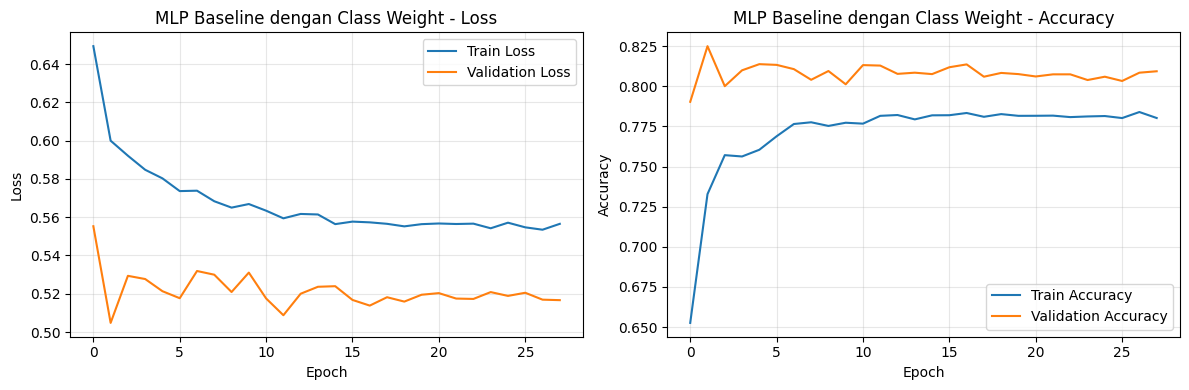

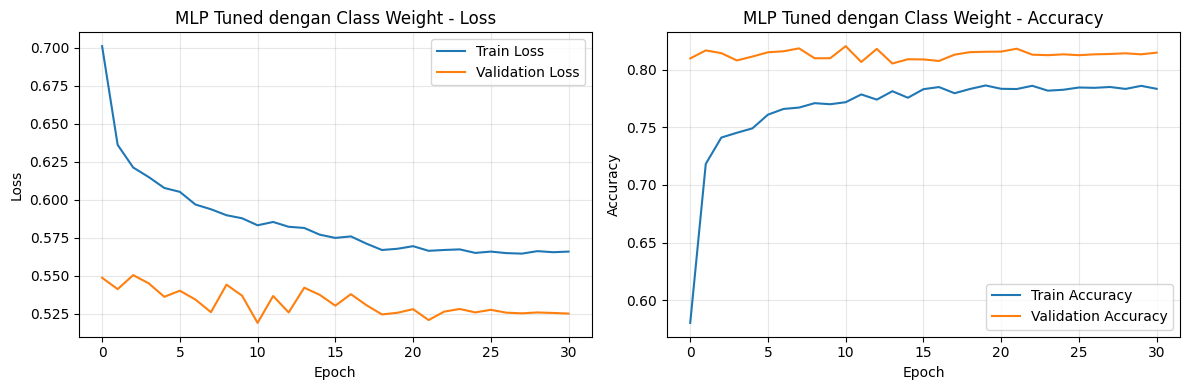

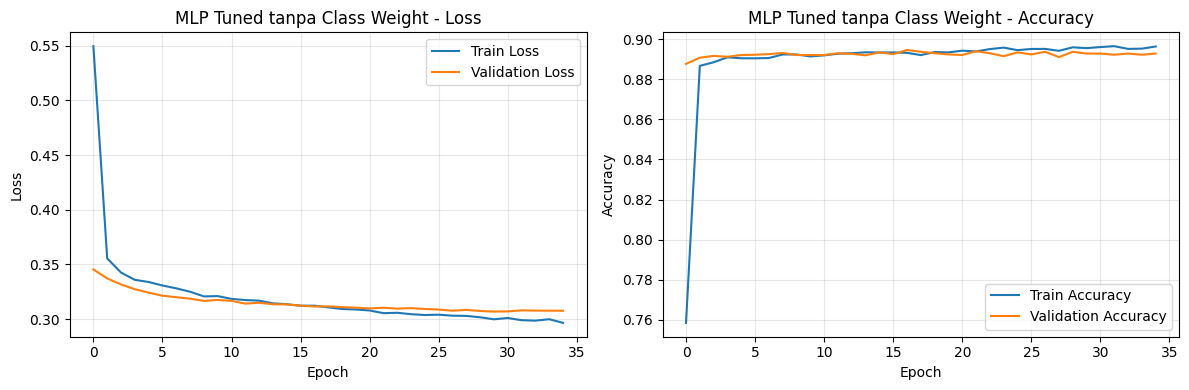

In [ ]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Grafik Loss
    axes[0].plot(history.history["loss"], label="Train Loss")
    axes[0].plot(history.history["val_loss"], label="Validation Loss")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Grafik Accuracy
    axes[1].plot(history.history["accuracy"], label="Train Accuracy")
    axes[1].plot(history.history["val_accuracy"], label="Validation Accuracy")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_history(history_baseline, "MLP Baseline dengan Class Weight")
plot_history(history_tuned, "MLP Tuned dengan Class Weight")
plot_history(history_no_weight, "MLP Tuned tanpa Class Weight")

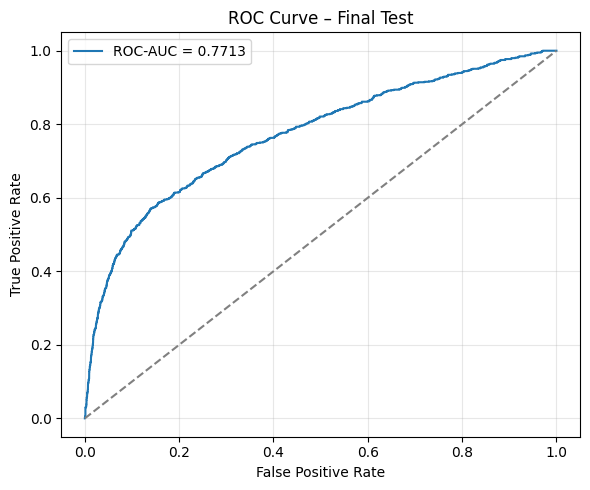

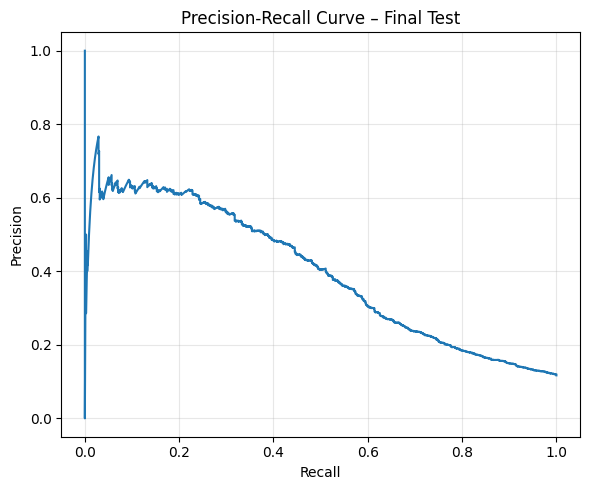

In [ ]:
fpr, tpr, _ = roc_curve(y_test, test_selected_probs)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_test, test_selected_probs):.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Final Test")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_selected_probs)
plt.figure(figsize=(6, 5))
plt.plot(recall_curve, precision_curve)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – Final Test")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

16. Interpretabilitas – Permutation Importance

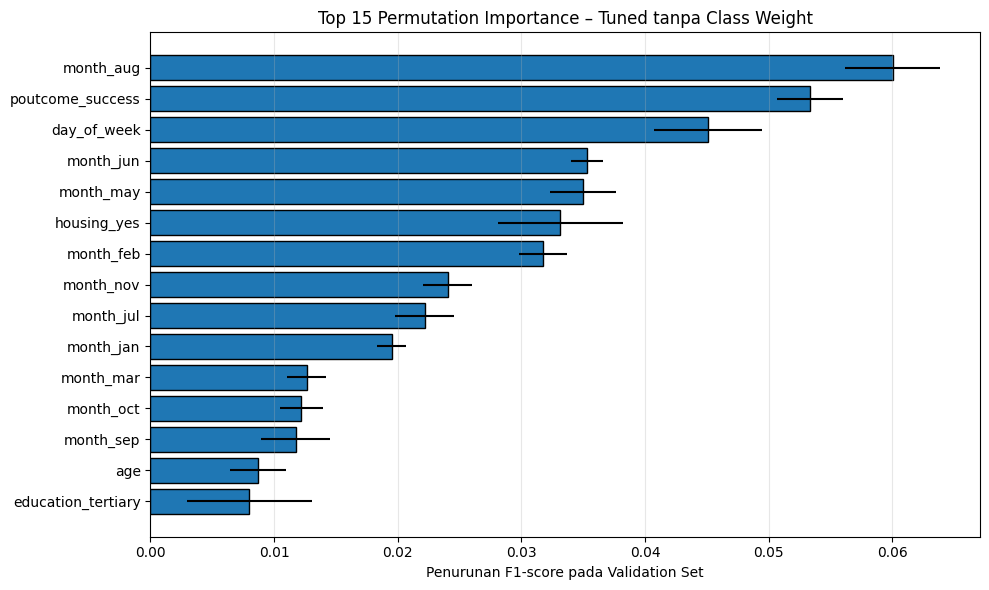

,Fitur,Mean F1 decrease,Std
0,month_aug,0.06004,0.00386
1,poutcome_success,0.05338,0.00267
2,day_of_week,0.04512,0.00436
3,month_jun,0.03528,0.00129
4,month_may,0.03498,0.00264
5,housing_yes,0.03316,0.00507
6,month_feb,0.03175,0.00196
7,month_nov,0.02403,0.00202
8,month_jul,0.02218,0.00242
9,month_jan,0.01950,0.00119


In [ ]:
class KerasProbabilityWrapper:
    """Wrapper sederhana agar model Keras dapat dipakai oleh permutation_importance."""
    def __init__(self, model):
        self.model = model

    def fit(self, X, y=None):
        return self

    def predict(self, X):
        return self.model.predict(X, verbose=0).ravel()

wrapped_model = KerasProbabilityWrapper(selected_model)

def validation_f1_scorer(estimator, X_eval, y_eval):
    probabilities = estimator.predict(X_eval)
    predictions = (probabilities >= best_threshold).astype(int)
    return f1_score(y_eval, predictions, zero_division=0)

importance_result = permutation_importance(
    wrapped_model,
    X_val_scaled,
    y_val,
    scoring=validation_f1_scorer,
    n_repeats=5,
    random_state=SEED
)

importance_order = importance_result.importances_mean.argsort()[::-1]
top_n = min(15, len(feature_columns))
top_idx = importance_order[:top_n]
top_features = [feature_columns[i] for i in top_idx]
top_means = importance_result.importances_mean[top_idx]
top_stds = importance_result.importances_std[top_idx]

plt.figure(figsize=(10, 6))
plt.barh(
    range(top_n), top_means[::-1], xerr=top_stds[::-1],
    align="center", edgecolor="black"
)
plt.yticks(range(top_n), top_features[::-1])
plt.xlabel("Penurunan F1-score pada Validation Set")
plt.title(f"Top {top_n} Permutation Importance – {selected_name}")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

permutation_importance_table = pd.DataFrame({
    "Fitur": top_features,
    "Mean F1 decrease": top_means,
    "Std": top_stds
})
display(permutation_importance_table.round(5))

17. Ablation Study Empat Fitur Engineering

In [ ]:
engineered_features = [
    "pdays_contacted",
    "balance_per_age",
    "pdays_recency_group",
    "campaign_intensity"
]
X_without_engineered = X.drop(columns=engineered_features)

Xab_train_full, _, yab_train_full, _ = train_test_split(
    X_without_engineered, y,
    test_size=0.15, random_state=SEED, stratify=y
)
Xab_train, Xab_val, yab_train, yab_val = train_test_split(
    Xab_train_full, yab_train_full,
    test_size=0.1764705882, random_state=SEED,
    stratify=yab_train_full
)

num_ab = Xab_train.select_dtypes(include=np.number).columns.tolist()
cat_ab = [c for c in Xab_train.columns if c not in num_ab]
med_ab = Xab_train[num_ab].median()
mode_ab = {}
for col in cat_ab:
    vals = Xab_train[col].mode(dropna=True)
    mode_ab[col] = vals.iloc[0] if len(vals) else "unknown"

def preprocess_ablation(frame):
    data = frame.copy()
    for col in num_ab:
        data[col] = pd.to_numeric(data[col], errors="coerce").fillna(med_ab[col])
    for col in cat_ab:
        data[col] = data[col].fillna(mode_ab[col]).astype(str)
    return pd.get_dummies(data, drop_first=True, dtype=float)

Xab_train_enc = preprocess_ablation(Xab_train)
cols_ab = Xab_train_enc.columns.tolist()
Xab_val_enc = preprocess_ablation(Xab_val).reindex(
    columns=cols_ab, fill_value=0
)

scaler_ab = StandardScaler()
Xab_train_scaled = scaler_ab.fit_transform(Xab_train_enc).astype("float32")
Xab_val_scaled = scaler_ab.transform(Xab_val_enc).astype("float32")

yab_train_np = yab_train.to_numpy(dtype="int32")
yab_val_np = yab_val.to_numpy(dtype="int32")

if selected_uses_class_weight:
    weights_ab = compute_class_weight(
        class_weight="balanced",
        classes=np.array([0, 1]),
        y=yab_train
    )
    weight_map_ab = {
        0: float(weights_ab[0]),
        1: float(weights_ab[1])
    }
    sample_weights_ab = np.array(
        [weight_map_ab[int(label)] for label in yab_train_np],
        dtype="float32"
    )
    train_ab_dataset = (
        tf.data.Dataset.from_tensor_slices(
            (Xab_train_scaled, yab_train_np, sample_weights_ab)
        )
        .shuffle(
            len(Xab_train_scaled),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )
else:
    train_ab_dataset = (
        tf.data.Dataset.from_tensor_slices(
            (Xab_train_scaled, yab_train_np)
        )
        .shuffle(
            len(Xab_train_scaled),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

val_ab_dataset = (
    tf.data.Dataset.from_tensor_slices((Xab_val_scaled, yab_val_np))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_without_engineered = build_mlp(
    Xab_train_scaled.shape[1],
    tuned=(selected_architecture == "Tuned")
)
history_without_engineered = model_without_engineered.fit(
    train_ab_dataset,
    validation_data=val_ab_dataset,
    epochs=100,
    callbacks=make_callbacks(),
    verbose=1
)

prob_without_engineered = get_prob(
    model_without_engineered,
    Xab_val_scaled
)

ablation_validation = pd.DataFrame([
    metric_row(
        yab_val,
        prob_without_engineered,
        0.50,
        "Tanpa empat fitur engineered @ 0.50"
    ),
    metric_row(
        y_val,
        selected_val_probs,
        0.50,
        "Dengan empat fitur engineered @ 0.50"
    )
])
display(ablation_validation.round(4))

Epoch 1/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7710 - loss: 0.5362 - pr_auc: 0.1940 - roc_auc: 0.6197 - val_accuracy: 0.8884 - val_loss: 0.3416 - val_pr_auc: 0.3386 - val_roc_auc: 0.7109 - learning_rate: 3.0000e-04
Epoch 2/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8854 - loss: 0.3551 - pr_auc: 0.3072 - roc_auc: 0.6875 - val_accuracy: 0.8902 - val_loss: 0.3339 - val_pr_auc: 0.3669 - val_roc_auc: 0.7340 - learning_rate: 3.0000e-04
Epoch 3/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8892 - loss: 0.3412 - pr_auc: 0.3414 - roc_auc: 0.7147 - val_accuracy: 0.8924 - val_loss: 0.3293 - val_pr_auc: 0.3837 - val_roc_auc: 0.7432 - learning_rate: 3.0000e-04
Epoch 4/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8895 - loss: 0.3337 - pr_auc: 0.3613 - roc_auc: 0.7313 - val_accuracy: 0.8935 - val_loss: 0.3255 - val_pr_auc: 0.3923 - val_roc_auc: 0.7474 - learning_rate: 3.0000e-04
Epoch 5/100
495/495 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accur

,Skenario,Threshold,Accuracy,Precision_yes,Recall_yes,F1_yes,ROC_AUC,PR_AUC
0,Tanpa empat fitur engineered @ 0.50,0.5,0.8953,0.6352,0.2459,0.3545,0.7745,0.4310
1,Dengan empat fitur engineered @ 0.50,0.5,0.8937,0.6241,0.2282,0.3343,0.7729,0.4391


18. Kesimpulan otomatis berdasarkan hasil eksekusi

In [ ]:
final_metrics = test_results.iloc[0]
selected_validation_metrics = threshold_comparison[
    threshold_comparison["Skenario"] == selected_name
].iloc[0]

print(f"Model final terpilih: {selected_name}")
print(f"Arsitektur: {selected_architecture}")
print(f"Class weighting: {selected_uses_class_weight}")
print(f"Threshold terpilih (validation): {best_threshold:.2f}")
print(f"F1 kelas Yes pada validation: {selected_validation_metrics['F1_yes']:.4f}")
print(f"F1 kelas Yes pada test: {final_metrics['F1_yes']:.4f}")
print(f"Precision Yes pada test: {final_metrics['Precision_yes']:.4f}")
print(f"Recall Yes pada test: {final_metrics['Recall_yes']:.4f}")
print(f"Accuracy pada test: {final_metrics['Accuracy']:.4f}")
print(f"ROC-AUC pada test: {final_metrics['ROC_AUC']:.4f}")
print(f"PR-AUC pada test: {final_metrics['PR_AUC']:.4f}")

print("Catatan interpretasi:")
print("Pemilihan model dan threshold dilakukan berdasarkan validation set.")
print("Test set hanya digunakan untuk evaluasi akhir model yang telah dipilih.")
print("Threshold tuning mengubah trade-off precision dan recall, bukan ROC-AUC/PR-AUC.")
print("Class weighting tidak selalu meningkatkan seluruh metrik; interpretasikan hasil setiap skenario.")

Model final terpilih: Tuned tanpa Class Weight
Arsitektur: Tuned
Class weighting: False
Threshold terpilih (validation): 0.20
F1 kelas Yes pada validation: 0.4663
F1 kelas Yes pada test: 0.4482
Precision Yes pada test: 0.4312
Recall Yes pada test: 0.4666
Accuracy pada test: 0.8657
ROC-AUC pada test: 0.7713
PR-AUC pada test: 0.3959
Catatan interpretasi:
Pemilihan model dan threshold dilakukan berdasarkan validation set.
Test set hanya digunakan untuk evaluasi akhir model yang telah dipilih.
Threshold tuning mengubah trade-off precision dan recall, bukan ROC-AUC/PR-AUC.
Class weighting tidak selalu meningkatkan seluruh metrik; interpretasikan hasil setiap skenario.


19. Menyimpan model dan artefak untuk Streamlit

In [ ]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Simpan model yang dipilih berdasarkan hasil validation set.
selected_model.save(ARTIFACT_DIR / "bank_marketing_mlp.keras")
joblib.dump(scaler, ARTIFACT_DIR / "scaler.pkl")
joblib.dump(feature_columns, ARTIFACT_DIR / "feature_columns.pkl")

preprocessing_metadata = {
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "medians": medians.to_dict(),
    "modes": modes,
    "raw_input_columns": X.columns.tolist(),
    "threshold": float(best_threshold),
    "selected_model": str(selected_name),
    "selected_architecture": str(selected_architecture),
    "uses_class_weight": bool(selected_uses_class_weight),
    "baseline_threshold": float(baseline_threshold),
    "tuned_threshold": float(tuned_threshold),
    "no_weight_threshold": float(no_weight_threshold),
    "class_weight": class_weight_dict,
    "added_features": added_features,
    "excluded_features": ["duration"],
    "input_dim": len(feature_columns),
    "seed": SEED
}
joblib.dump(
    preprocessing_metadata,
    ARTIFACT_DIR / "preprocessing_metadata.pkl"
)

# Simpan tabel perbandingan dan metrik untuk dokumentasi/evaluasi.
test_results.to_csv(ARTIFACT_DIR / "test_metrics.csv", index=False)
validation_comparison.to_csv(
    ARTIFACT_DIR / "validation_comparison.csv",
    index=False
)
threshold_comparison.to_csv(
    ARTIFACT_DIR / "threshold_comparison.csv",
    index=False
)
class_weight_comparison.to_csv(
    ARTIFACT_DIR / "class_weight_comparison.csv",
    index=False
)
permutation_importance_table.to_csv(
    ARTIFACT_DIR / "permutation_importance.csv",
    index=False
)
ablation_validation.to_csv(
    ARTIFACT_DIR / "ablation_validation.csv",
    index=False
)

model_info = {
    "selected_model": str(selected_name),
    "selected_architecture": str(selected_architecture),
    "uses_class_weight": bool(selected_uses_class_weight),
    "threshold": float(best_threshold),
    "input_dim": len(feature_columns),
    "seed": SEED,
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "sklearn_version": sklearn.__version__
}
with open(
    ARTIFACT_DIR / "model_info.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(model_info, file, indent=2, ensure_ascii=False)

print("Artefak tersimpan:")
for path in sorted(ARTIFACT_DIR.iterdir()):
    print("-", path.name)

Artefak tersimpan:
- ablation_validation.csv
- bank_marketing_mlp.keras
- class_weight_comparison.csv
- feature_columns.pkl
- model_info.json
- permutation_importance.csv
- preprocessing_metadata.pkl
- scaler.pkl
- test_metrics.csv
- threshold_comparison.csv
- validation_comparison.csv
